### Install & Import Libraries

In [2]:
!pip install -q transformers datasets evaluate scikit-learn emoji

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 27.3 MB/s eta 0:00:00


In [3]:
!pip install -U huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 798.3/798.3 kB 20.6 MB/s eta 0:00:00
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.29.0
    Uninstalling huggingface_hub-1.29.0:
      Successfully uninstalled huggingface_hub-1.29.0


In [4]:
from huggingface_hub import login

login()

In [5]:
!pip install emoji

In [6]:
import pandas as pd
import numpy as np
import ast
import re
import emoji
import torch

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("GPU available:", torch.cuda.is_available())

GPU available: True


In [7]:
import os

# Universal Environment Detector (Local VS Code / Google Colab)
try:
    from google.colab import files
    print("Running in Google Colab. Please upload dataset CSVs if not present:")
    uploaded = files.upload()
    for file_name in uploaded.keys():
        print("✓ Uploaded:", file_name)
except ImportError:
    print("✓ Running locally in VS Code / Jupyter environment.")
    print("✓ Dataset directory detected at 'data/':")
    if os.path.exists("data"):
        for f in os.listdir("data"):
            if f.endswith(".csv"):
                print("  •", f)


Saving complete_laptop_train.csv to complete_laptop_train.csv
Saving complete_laptop_test.csv to complete_laptop_test.csv
Saving Multilingual_Meesho_Review_Dataset.csv to Multilingual_Meesho_Review_Dataset.csv
Saving Complete_restaurant_train.csv to Complete_restaurant_train.csv
Saving Complete_restaurant_test.csv to Complete_restaurant_test.csv

Uploaded files:
✓ complete_laptop_train.csv
✓ complete_laptop_test.csv
✓ Multilingual_Meesho_Review_Dataset.csv
✓ Complete_restaurant_train.csv
✓ Complete_restaurant_test.csv


### Load ABSA-Mix

What are we doing?

ABSA-Mix already contains:

Review
   +
Aspect
   +
Sentiment

In [8]:
import os
import ast
import pandas as pd

def parse_list(value):
    try:
        return ast.literal_eval(value)
    except:
        return []

def load_absa(file_path, domain):
    # Auto-resolve local 'data/' directory path if running locally
    if not os.path.exists(file_path) and os.path.exists(os.path.join("data", file_path)):
        file_path = os.path.join("data", file_path)

    df = pd.read_csv(file_path)

    df["aspect_terms"] = df["aspect_terms"].apply(parse_list)
    df["at_polarity"] = df["at_polarity"].apply(parse_list)

    rows = []

    for _, row in df.iterrows():
        aspects = row["aspect_terms"]
        sentiments = row["at_polarity"]

        for aspect, sentiment in zip(aspects, sentiments):
            # Ignore conflict for our 3-class model
            if sentiment == "conflict":
                continue

            rows.append({
                "text": row["sentence"],
                "aspect": aspect,
                "sentiment": sentiment,
                "domain": domain
            })

    return pd.DataFrame(rows)


In [9]:
restaurant_train = load_absa(
    "Complete_restaurant_train.csv",
    "restaurant"
)

restaurant_test = load_absa(
    "Complete_restaurant_test.csv",
    "restaurant"
)

laptop_train = load_absa(
    "complete_laptop_train.csv",
    "laptop"
)

laptop_test = load_absa(
    "complete_laptop_test.csv",
    "laptop"
)

In [10]:
train_df = pd.concat(
    [restaurant_train, laptop_train],
    ignore_index=True
)

test_df = pd.concat(
    [restaurant_test, laptop_test],
    ignore_index=True
)

print("Training samples:", len(train_df))
print("Testing samples :", len(test_df))

display(train_df.head(10))

Training samples: 5879
Testing samples : 1733


,text,aspect,sentiment,domain
0,यह सबसे बड़ा place है जो most joints से अलग ade...,seating,positive,restaurant
1,यह सबसे बड़ा place है जो most joints से अलग ade...,bar,positive,restaurant
2,यह सबसे बड़ा place है जो most joints से अलग ade...,place,positive,restaurant
3,इस restaurant को pass करने के कुछ समय बाद मैंन...,dinner,neutral,restaurant
4,अगर मैं यहाँ के people को rate कर सकता तो यह p...,people,positive,restaurant
5,अगर मैं यहाँ के people को rate कर सकता तो यह p...,pizza,negative,restaurant
6,Rice to fish ration अच्छा था - उन्होंने rice क...,Rice to fish ration,positive,restaurant
7,Rice to fish ration अच्छा था - उन्होंने rice क...,rice,positive,restaurant
8,"मेरे husband ने कहा कि portions बहुत small थे,...",portions,negative,restaurant
9,"मेरे husband ने कहा कि portions बहुत small थे,...",portion,positive,restaurant


### Check ABSA Dataset
Before training, we make sure our data actually looks correct.

In [11]:
print("===== TRAINING DATA =====")

print("\nShape:", train_df.shape)

print("\nSentiment distribution:")
print(train_df["sentiment"].value_counts())

print("\nDomain distribution:")
print(train_df["domain"].value_counts())

print("\nSample:")
display(train_df.sample(10, random_state=42))

===== TRAINING DATA =====

Shape: (5879, 4)

Sentiment distribution:
sentiment
positive    3137
negative    1660
neutral     1082
Name: count, dtype: int64

Domain distribution:
domain
restaurant    3577
laptop        2302
Name: count, dtype: int64

Sample:


,text,aspect,sentiment,domain
5370,"इसलिए एक brief summary में, मुझे यह कहना होगा ...",setup,negative,laptop
5299,Supplied software: Windows के साथ जो आता है उस...,Supplied software,neutral,laptop
199,Reality में (potential diners को maximize करने...,reservations,negative,restaurant
3268,हमारे पास 3 hours का brunch था - वे बिलकुल भी ...,brunch,positive,restaurant
3504,Service कमाल का है और मेरा crab-cake eggs bene...,Service,positive,restaurant
5584,इसका priced बहुत reasonable है और box से निकाल...,priced,positive,laptop
2344,हमने dumpling menu से yummy dumplings का meal ...,dumplings,positive,restaurant
1611,यह secret है कि lunch menu जो हर entree ordere...,entree,positive,restaurant
5754,यह मेरे desktop की तुलना में बहुत fast है जो 2...,Core2 Quad,neutral,laptop
2201,"Rushed service के अलावा, हम food और drinks से ...",food,positive,restaurant


### Text Cleaning
Basic cleaning without destroying useful sentiment information.

In [12]:
def clean_text(text):

    text = str(text)

    # Remove URLs
    text = re.sub(
        r"http\S+|www\S+",
        "",
        text
    )

    # Normalize repeated characters
    # e.g. goooood -> good
    text = re.sub(
        r"(.)\1{2,}",
        r"\1\1",
        text
    )

    # Convert emoji into text representation
    text = emoji.demojize(
        text,
        delimiters=(" :", ": ")
    )

    # Remove extra spaces
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text

In [13]:
train_df["clean_text"] = train_df["text"].apply(clean_text)
test_df["clean_text"] = test_df["text"].apply(clean_text)

### Prepare Labels + Train/Validation Split

*Our model has 3 sentiment classes:*

negative → 0,
neutral  → 1,
positive → 2, *italicised text*


In [14]:
LABELS = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

ID_TO_LABEL = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

train_df["label"] = train_df["sentiment"].map(LABELS)
test_df["label"] = test_df["sentiment"].map(LABELS)

print(train_df["label"].value_counts())

label
2    3137
0    1660
1    1082
Name: count, dtype: int64


*Now create validation data from training data:*

In [15]:
from sklearn.model_selection import train_test_split

train_part, val_part = train_test_split(
    train_df,
    test_size=0.15,
    random_state=42,
    stratify=train_df["label"]
)

print("Train:", train_part.shape)
print("Validation:", val_part.shape)
print("Test:", test_df.shape)

Train: (4997, 6)
Validation: (882, 6)
Test: (1733, 6)


### Fine-tune IndicBERT

*This is the actual Aspect-Based Sentiment Classification.*

**The model receives** :
*Review + Aspect*

**and predicts** :
*Positive / Negative / Neutral*

In [16]:
MODEL_NAME = "ai4bharat/indic-bert"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

config.json:   0%|          | 0.00/507 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/5.65M [00:00<?, ?B/s]

Tokenization:

In [17]:
def tokenize_function(batch):

    return tokenizer(
        batch["clean_text"],
        batch["aspect"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

Convert to Hugging Face datasets:

In [18]:
train_ds = Dataset.from_pandas(
    train_part[
        ["clean_text", "aspect", "label"]
    ]
)

val_ds = Dataset.from_pandas(
    val_part[
        ["clean_text", "aspect", "label"]
    ]
)

test_ds = Dataset.from_pandas(
    test_df[
        ["clean_text", "aspect", "label"]
    ]
)

In [19]:
train_ds = train_ds.map(
    tokenize_function,
    batched=True
)

val_ds = val_ds.map(
    tokenize_function,
    batched=True
)

test_ds = test_ds.map(
    tokenize_function,
    batched=True
)

Map:   0%|          | 0/4997 [00:00<?, ? examples/s]

Map:   0%|          | 0/882 [00:00<?, ? examples/s]

Map:   0%|          | 0/1733 [00:00<?, ? examples/s]

### Train the Model

In [20]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  135MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/25 [00:00<?, ?it/s]

[transformers] AlbertForSequenceClassification LOAD REPORT from: ai4bharat/indic-bert
Key                              | Status     | 
---------------------------------+------------+-
predictions.bias                 | UNEXPECTED | 
sop_classifier.classifier.weight | UNEXPECTED | 
predictions.LayerNorm.bias       | UNEXPECTED | 
predictions.LayerNorm.weight     | UNEXPECTED | 
predictions.decoder.bias         | UNEXPECTED | 
predictions.dense.bias           | UNEXPECTED | 
predictions.decoder.weight       | UNEXPECTED | 
sop_classifier.classifier.bias   | UNEXPECTED | 
predictions.dense.weight         | UNEXPECTED | 
classifier.weight                | MISSING    | 
classifier.bias                  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Metrics:

In [21]:
def compute_metrics(eval_pred):

    predictions, labels = eval_pred

    predictions = np.argmax(
        predictions,
        axis=-1
    )

    return {
        "accuracy": accuracy_score(
            labels,
            predictions
        ),
        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro"
        )
    }

Training configuration:

In [22]:
training_args = TrainingArguments(

    output_dir="./sentimix_results",

    eval_strategy="epoch",

    save_strategy="epoch",

    learning_rate=2e-5,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=32,

    num_train_epochs=3,

    weight_decay=0.01,

    load_best_model_at_end=True,

    metric_for_best_model="macro_f1",

    report_to="none"
)

Trainer:

In [23]:
trainer = Trainer(

    model=model,

    args=training_args,

    train_dataset=train_ds,

    eval_dataset=val_ds,

    compute_metrics=compute_metrics
)
trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  135MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,No log,0.863853,0.628118,0.426661
2,0.885161,0.749810,0.683673,0.495228
3,0.885161,0.725608,0.707483,0.601501


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=939, training_loss=0.79564860936044, metrics={'train_runtime': 298.8081, 'train_samples_per_second': 50.169, 'train_steps_per_second': 3.142, 'total_flos': 89572964435712.0, 'train_loss': 0.79564860936044, 'epoch': 3.0})

In [27]:
import os

# Configure Save Path for Local Machine or Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    SAVE_PATH = "/content/drive/MyDrive/SentiMix_Model"
except ImportError:
    SAVE_PATH = "results/saved_models/sentimix_transformer"
    os.makedirs(SAVE_PATH, exist_ok=True)

print("Save destination set to:", SAVE_PATH)


Mounted at /content/drive


In [28]:
SAVE_PATH = "/content/drive/MyDrive/SentiMix_Model"

trainer.save_model(SAVE_PATH)
tokenizer.save_pretrained(SAVE_PATH)

print("Model saved successfully!")
print("Location:", SAVE_PATH)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully!
Location: /content/drive/MyDrive/SentiMix_Model


In [29]:
test_results = trainer.evaluate(test_ds)
print(test_results)

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.885161,0.729608,3,0.691864,0.531561


{'eval_loss': 0.7296078205108643, 'eval_accuracy': 0.6918638199653779, 'eval_macro_f1': 0.5315609574827153}


### Final Evaluation

Now we finally touch the test dataset.

In [30]:
predictions = trainer.predict(test_ds)

y_pred = np.argmax(
    predictions.predictions,
    axis=1
)

y_true = test_df["label"].values

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "negative",
            "neutral",
            "positive"
        ]
    )
)

              precision    recall  f1-score   support

    negative       0.49      0.68      0.57       322
     neutral       0.46      0.12      0.19       357
    positive       0.79      0.89      0.83      1054

    accuracy                           0.69      1733
   macro avg       0.58      0.56      0.53      1733
weighted avg       0.66      0.69      0.65      1733



### Domain-wise Evaluation

We want to know :
Is the model working similarly on restaurant and laptop data?

In [31]:
for domain in ["restaurant", "laptop"]:

    mask = (
        test_df["domain"] == domain
    ).values

    print("\n==============================")
    print(f"DOMAIN: {domain.upper()}")
    print("==============================")

    print(
        classification_report(
            y_true[mask],
            y_pred[mask],
            target_names=[
                "negative",
                "neutral",
                "positive"
            ]
        )
    )


DOMAIN: RESTAURANT
              precision    recall  f1-score   support

    negative       0.53      0.59      0.56       195
     neutral       0.39      0.11      0.17       189
    positive       0.79      0.91      0.84       713

    accuracy                           0.72      1097
   macro avg       0.57      0.54      0.53      1097
weighted avg       0.67      0.72      0.68      1097


DOMAIN: LAPTOP
              precision    recall  f1-score   support

    negative       0.45      0.81      0.58       127
     neutral       0.56      0.13      0.21       168
    positive       0.78      0.84      0.81       341

    accuracy                           0.65       636
   macro avg       0.60      0.60      0.53       636
weighted avg       0.66      0.65      0.61       636



Confusion Matrix :

This shows where the model is getting confused.

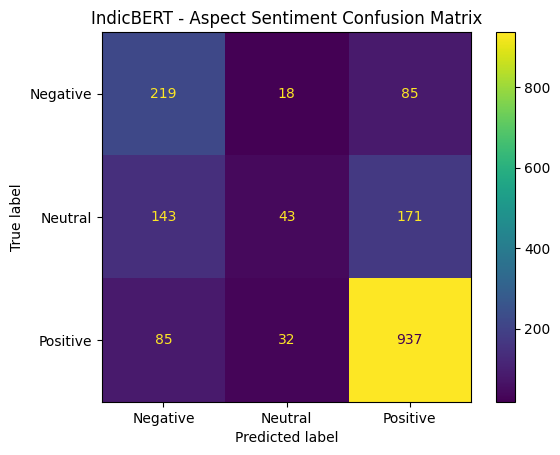

In [32]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Negative",
        "Neutral",
        "Positive"
    ]
)

disp.plot()

plt.title(
    "IndicBERT - Aspect Sentiment Confusion Matrix"
)

plt.show()

### Load Meesho Dataset
Now we move to our actual target domain: e-commerce.

Meesho is not used for training this model yet because it doesn't have aspect-level gold labels.




In [33]:
meesho_df = pd.read_csv(
    "Multilingual_Meesho_Review_Dataset.csv"
)

meesho_df = meesho_df.dropna(
    subset=["comments"]
).reset_index(drop=True)

print("Meesho reviews:", len(meesho_df))

print("\nColumns:")
print(meesho_df.columns.tolist())

display(
    meesho_df[
        [
            "product_name",
            "comments",
            "ratings",
            "mapped_sentiment",
            "category"
        ]
    ].head(10)
)

Meesho reviews: 1005

Columns:
['id', 'product_name', 'reviewer', 'date', 'ratings', 'comments', 'mapped_sentiment', 'images', 'source', 'helpful', 'category']


,product_name,comments,ratings,mapped_sentiment,category
0,Womens Ethnic Embroidery Top Pant And Dupatta Set,very nice quality of this suit it is having th...,5,very good,Fashion
1,Womens Ethnic Embroidery Top Pant And Dupatta Set,Oh my god What a quality 🫶 What a fabric 🫶 Fit...,5,very good,Fashion
2,Womens Ethnic Embroidery Top Pant And Dupatta Set,Fabric quality is superb it is khadi cotton. T...,5,very good,Fashion
3,Womens Ethnic Embroidery Top Pant And Dupatta Set,Thank you to the seller and also to the meesho...,5,very good,Fashion
4,Womens Ethnic Embroidery Top Pant And Dupatta Set,Fabric bahut achcha hai aur design bhi bahut a...,5,very good,Fashion
5,Womens Ethnic Embroidery Top Pant And Dupatta Set,Liked the set.... it's not cotton but mixed ov...,5,very good,Fashion
6,Womens Ethnic Embroidery Top Pant And Dupatta Set,"Bhut hi pyara suit aaya h ,🥰😘😚😍😘🥰😍ise aap log ...",5,very good,Fashion
7,Womens Ethnic Embroidery Top Pant And Dupatta Set,The kurti is delivered exactly the same as sho...,5,very good,Fashion
8,Womens Ethnic Embroidery Top Pant And Dupatta Set,Super .. everything is good .. Fabric is ok. I...,5,very good,Fashion
9,Womens Ethnic Embroidery Top Pant And Dupatta Set,Dress is so good. Quality is amazing. It fits ...,5,very good,Fashion


Prepare Meesho Reviews

In [34]:
meesho_df["clean_text"] = (
    meesho_df["comments"]
    .apply(clean_text)
)

In [35]:
HINDI_ROMAN_WORDS = {
    "hai", "hain", "tha", "thi", "the",
    "nahi", "nahin",
    "bahut", "bohot",
    "acha", "accha", "achha",
    "bekar", "bekaar",
    "sahi", "mast", "badhiya",
    "kharab", "khrab",
    "paisa", "paise",
    "ka", "ki", "ke", "ko",
    "se", "me", "mein",
    "mera", "meri", "mere",
    "mujhe", "mujh",
    "ye", "yeh",
    "wo", "woh",
    "zyada", "kam",
    "lagta", "lagti",
    "mila", "mili",
    "dikkat",
    "pasand",
    "bilkul",
    "theek",
    "chahiye"
}


def is_hinglish(text):

    tokens = re.findall(
        r"[a-zA-Z]+",
        str(text).lower()
    )

    if len(tokens) < 3:
        return False

    hindi_count = sum(
        word in HINDI_ROMAN_WORDS
        for word in tokens
    )

    english_count = sum(
        word not in HINDI_ROMAN_WORDS
        for word in tokens
    )

    return (
        hindi_count >= 1
        and english_count >= 1
    )

In [36]:
meesho_df["is_hinglish"] = (
    meesho_df["clean_text"]
    .apply(is_hinglish)
)

hinglish_meesho = meesho_df[
    meesho_df["is_hinglish"]
].copy()

print(
    "Hinglish candidates:",
    len(hinglish_meesho)
)

display(
    hinglish_meesho[
        [
            "product_name",
            "clean_text",
            "ratings",
            "category"
        ]
    ].head(20)
)

Hinglish candidates: 269


,product_name,clean_text,ratings,category
1,Womens Ethnic Embroidery Top Pant And Dupatta Set,Oh my god What a quality :heart_hands: What a ...,5,Fashion
2,Womens Ethnic Embroidery Top Pant And Dupatta Set,Fabric quality is superb it is khadi cotton. T...,5,Fashion
3,Womens Ethnic Embroidery Top Pant And Dupatta Set,Thank you to the seller and also to the meesho...,5,Fashion
4,Womens Ethnic Embroidery Top Pant And Dupatta Set,Fabric bahut achcha hai aur design bhi bahut a...,5,Fashion
5,Womens Ethnic Embroidery Top Pant And Dupatta Set,Liked the set.. it's not cotton but mixed over...,5,Fashion
6,Womens Ethnic Embroidery Top Pant And Dupatta Set,"Bhut hi pyara suit aaya h , :smiling_face_with...",5,Fashion
7,Womens Ethnic Embroidery Top Pant And Dupatta Set,The kurti is delivered exactly the same as sho...,5,Fashion
8,Womens Ethnic Embroidery Top Pant And Dupatta Set,Super .. everything is good .. Fabric is ok. I...,5,Fashion
10,Womens Ethnic Embroidery Top Pant And Dupatta Set,beyond expectation.. amazing febric I felt ver...,5,Fashion
14,Womens Ethnic Embroidery Top Pant And Dupatta Set,OMG :flushed_face: kya tarif Karu eski jabarda...,5,Fashion
